# Mooring Plotly Multi - Choose multiple datastreams

In [3]:
import plotly.express as px
import plotly.graph_objects as go

In [4]:
import pandas as pd
import xarray as xr
import datetime
import EcoFOCIpy.io.erddap as erddap

In [5]:
timeseries ={'url':"http://ecofoci-field.pmel.noaa.gov:8080/erddap",
               'mooringid':'24ckp2a',
               'qclevel':'final',
               'instrid':'24ckp2a_suna_0040m'
              }
ts1 = erddap.erddapMooredInstretrieve(**timeseries)

ts1 = ts1.set_index(pd.DatetimeIndex(ts1['time (UTC)']))
ts1.columns = [x.split()[0] for x in ts1.columns]

ts1['doy']=ts1.index.dayofyear
ts1['year']=ts1.index.year

In [8]:
ts1

,time,latitude,longitude,depth,timeseries_id,Instrument_Identifier,Serial_Number,Water_Depth,doy,year
time (UTC),,,,,,,,,,
2024-08-16 10:00:00+00:00,2024-08-16T10:00:00Z,71.2157,-164.2494,40.0,24ckp2a_suna_0040m,SUNA,1468,45.0,229,2024
2024-08-16 11:00:00+00:00,2024-08-16T11:00:00Z,71.2157,-164.2494,40.0,24ckp2a_suna_0040m,SUNA,1468,45.0,229,2024
2024-08-16 12:00:00+00:00,2024-08-16T12:00:00Z,71.2157,-164.2494,40.0,24ckp2a_suna_0040m,SUNA,1468,45.0,229,2024
2024-08-16 13:00:00+00:00,2024-08-16T13:00:00Z,71.2157,-164.2494,40.0,24ckp2a_suna_0040m,SUNA,1468,45.0,229,2024
2024-08-16 14:00:00+00:00,2024-08-16T14:00:00Z,71.2157,-164.2494,40.0,24ckp2a_suna_0040m,SUNA,1468,45.0,229,2024
...,...,...,...,...,...,...,...,...,...,...
2025-08-20 21:00:00+00:00,2025-08-20T21:00:00Z,71.2157,-164.2494,40.0,24ckp2a_suna_0040m,SUNA,1468,45.0,232,2025
2025-08-20 22:00:00+00:00,2025-08-20T22:00:00Z,71.2157,-164.2494,40.0,24ckp2a_suna_0040m,SUNA,1468,45.0,232,2025
2025-08-20 23:00:00+00:00,2025-08-20T23:00:00Z,71.2157,-164.2494,40.0,24ckp2a_suna_0040m,SUNA,1468,45.0,232,2025


In [7]:
fig = go.Figure()
line = go.Scatter(x=ts1.index.dayofyear,
                  y=ts1['nitrates'].values,
                  mode='markers+lines',)
fig.add_trace(line)

KeyError: 'nitrates'

In [45]:
# fpath = '/Users/bell/Documents/EcoFOCI_FieldOps_Documentation/DataProcessingDocumentation/2. EcoFOCI_DataProcesssing_Records/moorings'

# ts2 = xr.load_dataset(f'{fpath}/2017/17bs4b/17bs4b_s37_0054m.nc')

In [46]:
timeseries ={'url':"http://ecofoci-field.pmel.noaa.gov:8080/erddap",
               'mooringid':'25bs2c',
               'qclevel':'final',
               'instrid':'23bsp14a_an9_0034m'
              }
ts2 = erddap.erddapMooredInstretrieve(**timeseries)

ts2 = ts2.set_index(pd.DatetimeIndex(ts2['time (UTC)']))
ts2.columns = [x.split()[0] for x in ts2.columns]


/Users/bell/mambaforge/envs/p312/lib/python3.12/site-packages/erddapy/core/interfaces.py:39: DtypeWarning: Columns (0: Instrument_Identifier) have mixed types. Specify dtype option on import or set low_memory=False.
  return pd.read_csv(data, **(pandas_kwargs or {}))


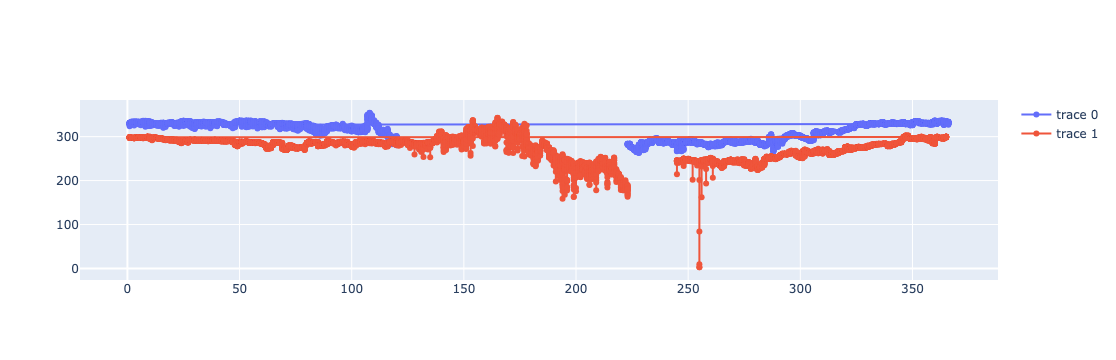

In [60]:
# ts2 = ts2.isel({'depth':0,'latitude':0,'longitude':0}).to_pandas()
    
line = go.Scatter(x=ts2.index.dayofyear,
                  y=ts2['oxygen_concentration'].values,
                  mode='markers+lines',)
fig.add_trace(line)

In [48]:
timeseries ={'url':"http://ecofoci-field.pmel.noaa.gov:8080/erddap",
               'mooringid':'20bsp14a',
               'qclevel':'final',
               'instrid':'20bsp14a_rcmsg_0033m'
              }
ts3 = erddap.erddapMooredInstretrieve(**timeseries)

ts3 = ts3.set_index(pd.DatetimeIndex(ts3['time (UTC)']))
ts3.columns = [x.split()[0] for x in ts3.columns]



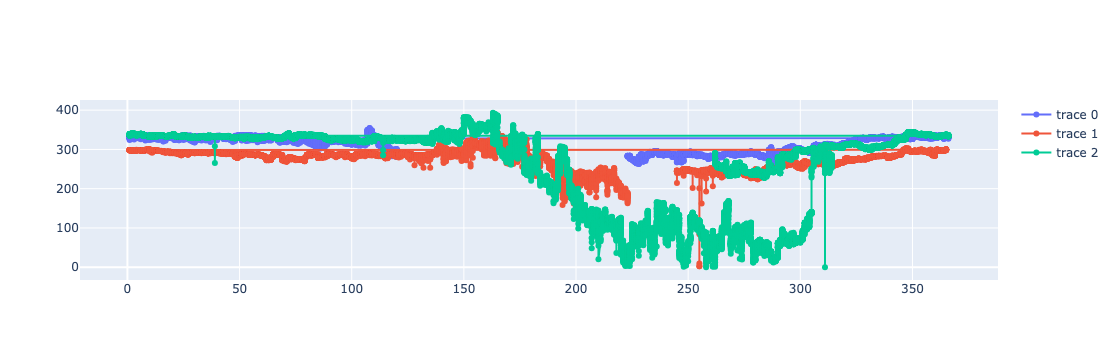

In [61]:
line = go.Scatter(x=ts3.index.dayofyear,
                  y=ts3['oxygen_concentration'].values,
                  mode='markers+lines',)
fig.add_trace(line)

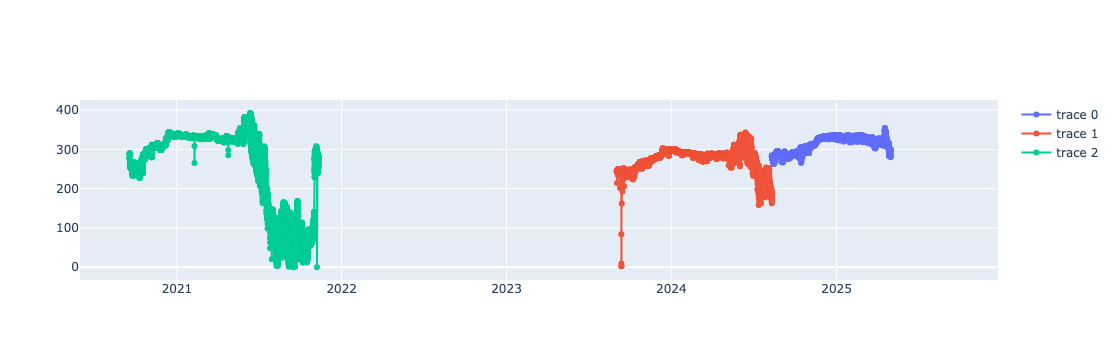

In [63]:
fig = go.Figure()
line = go.Scatter(x=ts1.index.values,
                  y=ts1['oxygen_concentration'].values,
                  mode='markers+lines',)
fig.add_trace(line)
line = go.Scatter(x=ts2.index.values,
                  y=ts2['oxygen_concentration'].values,
                  mode='markers+lines',)
fig.add_trace(line)
line = go.Scatter(x=ts3.index.values,
                  y=ts3['oxygen_concentration'].values,
                  mode='markers+lines',)
fig.add_trace(line)